In [21]:
# Steps

# Dataset Upload

# Grab the dataset: CO₂ Emissions Dataset (Kaggle)

# (CSV file: CO2 Emissions_Canada.csv)

# Exploration

# Print head, shape, and info.

# Check for missing values.

# Feature Selection

# Use features like Engine Size, Cylinders, Fuel Consumption City (L/100 km), etc.

# Target = CO2 Emissions (g/km)

# Train-Test Split + Scaling

# StandardScaler again (so that Ridge/Lasso don’t freak out).

# Model Training

# Train Linear, Ridge, and Lasso regression.

# Compare RMSE & R².

# Extra Fun Twist

# Plot predictions vs actuals.

# See how Lasso shrinks coefficients (some features → 0).

# Rank features by importance.

In [22]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge,Lasso,LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt

In [23]:
dataset=pd.read_csv('carbon_canada.csv')
print('File has been Read !')
print(dataset.head())#Gives u 1st 5 values of the table
print(dataset.info())#gives u (rows,columns)
print(dataset.shape)#print(dataset.shape)

File has been Read !
    Make       Model Vehicle Class  Engine Size(L)  Cylinders Transmission  \
0  ACURA         ILX       COMPACT             2.0          4          AS5   
1  ACURA         ILX       COMPACT             2.4          4           M6   
2  ACURA  ILX HYBRID       COMPACT             1.5          4          AV7   
3  ACURA     MDX 4WD   SUV - SMALL             3.5          6          AS6   
4  ACURA     RDX AWD   SUV - SMALL             3.5          6          AS6   

  Fuel Type  Fuel Consumption City (L/100 km)  \
0         Z                               9.9   
1         Z                              11.2   
2         Z                               6.0   
3         Z                              12.7   
4         Z                              12.1   

   Fuel Consumption Hwy (L/100 km)  Fuel Consumption Comb (L/100 km)  \
0                              6.7                               8.5   
1                              7.7                               9.6   

In [24]:
#EDA(Checking for null or missing values)
print(dataset.isnull().sum())

Make                                0
Model                               0
Vehicle Class                       0
Engine Size(L)                      0
Cylinders                           0
Transmission                        0
Fuel Type                           0
Fuel Consumption City (L/100 km)    0
Fuel Consumption Hwy (L/100 km)     0
Fuel Consumption Comb (L/100 km)    0
Fuel Consumption Comb (mpg)         0
CO2 Emissions(g/km)                 0
dtype: int64


In [25]:
#Handling Missing values
dataset= dataset.dropna()
dataset=dataset.dropna(axis=1)

In [26]:
#Splitting Into Features(x) and Target(y)
x=dataset[['Engine Size(L)', 'Cylinders', 'Fuel Consumption City (L/100 km)']] #Features
y=dataset['CO2 Emissions(g/km)']#Traget
print('Splitting Has Been Successfully Done !')

Splitting Has Been Successfully Done !


In [27]:
#training_testing

x_train,x_test,y_train,y_test= train_test_split(x,y,test_size=0.2,random_state=42) 
print('Training_Testing has deen done successfully !')

Training_Testing has deen done successfully !


In [28]:
#Feature Scaling
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)
print('Feature Scaling Has Been Done Successfully !')

Feature Scaling Has Been Done Successfully !


In [29]:
#Regularization/Regression/Model Training
model_r=Ridge(alpha=1.0)
model_l=Lasso(alpha=1.0)
model_li=LinearRegression()

model_r.fit(x_train_scaled,y_train)
model_l.fit(x_train_scaled,y_train)
model_li.fit(x_train_scaled,y_train)

print('Ridge,Lasso and Linear Regression has been done successfully !')

Ridge,Lasso and Linear Regression has been done successfully !


In [30]:
#We will predict all the 3 models and will choose the best among these 3 using r2_score, and rootmean_square_error/mean_square_error.
pred_1= model_r.predict(x_test_scaled)
print(f'Predictin using Ridge : {pred_1}')

pred_2= model_l.predict(x_test_scaled)
print(f'Predictin using Lasso : {pred_2}')

pred_3= model_li.predict(x_test_scaled)
print(f'Predictin using Ridge : {pred_3}')

print('Predictions Have Been Performed Successfully !')

Predictin using Ridge : [250.01341545 323.87642756 321.12805026 ... 189.53218273 247.38191957
 202.06607266]
Predictin using Lasso : [249.98021726 322.4946656  319.63747949 ... 190.69516728 247.34199256
 203.02361753]
Predictin using Ridge : [250.01376677 323.8877841  321.11678718 ... 189.53004376 247.37513029
 202.06256692]
Predictions Have Been Performed Successfully !


In [31]:
#Evaluating Model
#Using r2_score
r2_r=r2_score(pred_1,y_test)
print(f'r2_score from Ridge prediction(pred_1) is : {r2_r}')
r2_l=r2_score(pred_2,y_test)
print(f'r2_score from Lasso prediction(pred_2) is : {r2_l}')
r2_li=r2_score(pred_3,y_test)
print(f'r2_score from Linear Regression prediction(pred_3) is : {r2_li}')

#Using Mean_squared_error
mse_r= mean_squared_error(pred_1,y_test)
print(f'mean_square_error from Ridge prediction(pred_1) is : {mse_r}')

mse_l= mean_squared_error(pred_2,y_test)
print(f'mean_square_error from Lasso prediction(pred_2) is : {mse_l}')

mse_li= mean_squared_error(pred_3,y_test)
print(f'mean_square_error from Linear Regression prediction(pred_1) is : {mse_li}')




r2_score from Ridge prediction(pred_1) is : 0.8498343162890863
r2_score from Lasso prediction(pred_2) is : 0.8431499983319922
r2_score from Linear Regression prediction(pred_3) is : 0.8498650232924527
mean_square_error from Ridge prediction(pred_1) is : 440.88561549763665
mean_square_error from Lasso prediction(pred_2) is : 443.27408049146936
mean_square_error from Linear Regression prediction(pred_1) is : 440.88453524428644


In [32]:
# R² (coefficient of determination)

# Measures how much variance in target is explained by your model.

# Closer to 1 → better.

# If it’s negative → your model is doing worse than just predicting the mean 🤦‍♀️.

# RMSE (Root Mean Squared Error)

# Lower MSE = better (fewer squared errors).

# Measures error in the same unit as your target.

# Closer to 0 → better.

In [33]:
# Pred-3(Linear Regression) Won !in case of r2_score. It is the Most precised-one.
# Pred-3(Linear Regression) Won !in case of mse too![since,Lower MSE = better (fewer squared errors)]. It is the Most precised-one.
print('pred_3 is the Most precised One.')


pred_3 is the Most precised One.


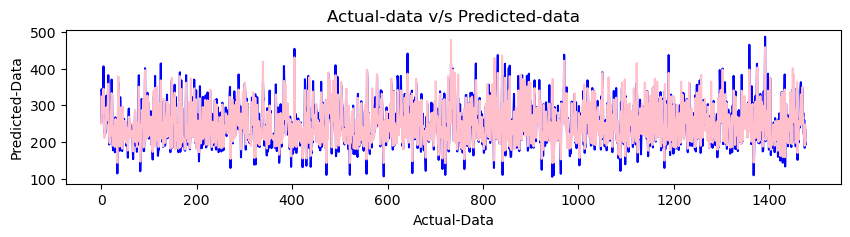

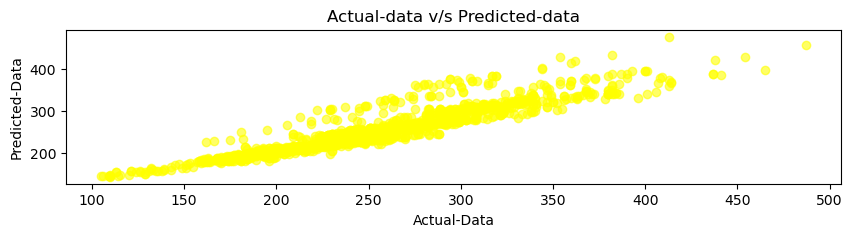

In [41]:
#Visulaizing/Plotting b/w actual data(y_test) and predicted data(pred-3)[Part Of EDA]
#Line Plot

plt.figure(figsize=(10,2))#hamesha figure plot krne se phle size deni hoti h.
plt.plot(y_test.values, color="blue")
plt.plot(pred_3,  color="pink")
plt.title('Actual-data v/s Predicted-data')
plt.xlabel('Actual-Data')
plt.ylabel('Predicted-Data')

plt.show()


#Scatter plot
plt.figure(figsize=(10,2))
plt.scatter(y_test,pred_3,color='yellow',alpha=0.6)
# alpha controls the transparency of your plot elements.
# Range = 0.0 → fully transparent (invisible) to 1.0 → fully opaque (solid color).

plt.title('Actual-data v/s Predicted-data')
plt.xlabel('Actual-Data')
plt.ylabel('Predicted-Data')

plt.show()
